# 04. N-gram khas dan analisis kesalahan

Pertanyaan yang dijawab:

1. Potongan huruf apa yang paling khas untuk tiap daerah?
2. Wilayah mana yang paling sering tertukar?
3. Apakah kesalahan model menyimpan jejak transmigrasi?
4. Adakah desa yang namanya sangat tidak cocok dengan provinsinya (kandidat salah kode wilayah)?

Hasil yang disimpan:

- `reports/ngram_khas_provinsi.csv`, `reports/ngram_khas_wilayah.csv`
- `data/processed/prediksi_oof.parquet` (tebakan out-of-fold untuk semua desa, dipakai dashboard)
- `data/processed/kandidat_salah_kode.csv`
- grafik `reports/figures/04_*.png`

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.peta import gambar_peta
from src.regions import WILAYAH, wilayah_dari_provinsi

PROCESSED = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
SEED = 42

# warna grafik (palet referensi dataviz)
BIRU, ORANYE, ABU, TEKS, TEKS2 = "#257de0", "#f47230", "#c2c2c2", "#191919", "#666666"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.titlecolor": TEKS, "font.size": 9,
})

df = pd.read_parquet(PROCESSED / "desa_clean.parquet")
PROVINSI_JAWA = set(WILAYAH["Jawa"])
print(df.shape)

(83758, 9)


## 1. N-gram paling khas tiap provinsi

Model Logistic Regression memberi satu bobot (koefisien) untuk setiap pasangan n-gram dan provinsi. Bobot positif yang besar berarti n-gram itu mendorong tebakan ke provinsi tersebut.

Cara membaca: tanda `_` adalah batas kata. Jadi `_ci` artinya kata yang **diawali** "ci", dan `way_` artinya kata yang **diakhiri** "way" (atau kata "way" itu sendiri).

Supaya tidak terkecoh n-gram langka, hanya n-gram yang muncul di minimal 30 nama yang dipakai. Kolom `persen_di_provinsi` menunjukkan berapa persen desa yang mengandung n-gram itu memang berada di provinsi tersebut.

In [2]:
def ngram_khas(model_path, target, top=10, min_nama=30):
    pipe = joblib.load(model_path)
    vec, lr = pipe.named_steps["tfidf"], pipe.named_steps["model"]
    fitur = vec.get_feature_names_out()
    X = vec.transform(df["nama_bersih"]) > 0
    jumlah_nama = np.asarray(X.sum(axis=0)).ravel()
    baris = []
    for k, kelas in enumerate(lr.classes_):
        koef = np.where(jumlah_nama >= min_nama, lr.coef_[k], -np.inf)
        di_kelas = (df[target] == kelas).values
        for rank, j in enumerate(np.argsort(-koef)[:top], start=1):
            ada = X[:, j].toarray().ravel()
            baris.append({
                target: kelas, "peringkat": rank, "ngram": fitur[j].replace(" ", "_"),
                "koefisien": round(float(lr.coef_[k, j]), 3),
                "jumlah_desa": int(ada.sum()),
                "persen_di_" + target: round(100 * float(di_kelas[ada].mean()), 1),
            })
    return pd.DataFrame(baris)

ng_prov = ngram_khas(ROOT / "models" / "best_provinsi.joblib", "provinsi")
ng_wil = ngram_khas(ROOT / "models" / "best_wilayah.joblib", "wilayah")
ng_prov.to_csv(ROOT / "reports" / "ngram_khas_provinsi.csv", index=False)
ng_wil.to_csv(ROOT / "reports" / "ngram_khas_wilayah.csv", index=False)

ringkas = ng_prov[ng_prov["peringkat"] <= 6].groupby("provinsi")["ngram"].apply(" | ".join)
ringkas.to_frame("6 n-gram paling khas")

,6 n-gram paling khas
provinsi,
Aceh,eu | e_ | h_ | ie | ue | t_
Bali,_ant | ggah | ukad | lat_ | beng | atur
Banten,_ci | ci | eu | _c | bend | panu
Bengkulu,o_ | aba_ | r_ | k_ | i_ | ebar
Daerah Istimewa Yogyakarta,_ng | _ngl | rt | gsar | wu | giri
Daerah Khusus Ibukota Jakarta,_c | _ci | kare | akas | ment | ci
Gorontalo,hu | mana | aa_ | ohu | ngo | o_
Jambi,o_ | n_ | _s | un_ | h_ | koto
Jawa Barat,_ci | ci | eu | _c | ja | _lor


In [3]:
ng_wil[ng_wil["peringkat"] <= 6].groupby("wilayah")["ngram"].apply(" | ".join).to_frame("6 n-gram paling khas")

,6 n-gram paling khas
wilayah,
Bali dan Nusa Tenggara,_oe | _nd | wae_ | _n | oe | wolo
Jawa,_ci | bend | ci | lor_ | weta | waru
Kalimantan,q_ | n_ | au_ | k_ | _se | ai_
Maluku,_ake | wae | nana | y_ | soa | _rum
Papua,_y | me_ | kla | _kla | tadi | gelo
Sulawesi,pp | rano | uu | kk | nr | _ue
Sumatera,eu | _s | h_ | k_ | t_ | way_


Grafik untuk slide: 9 provinsi dengan pola yang paling mudah dijelaskan.

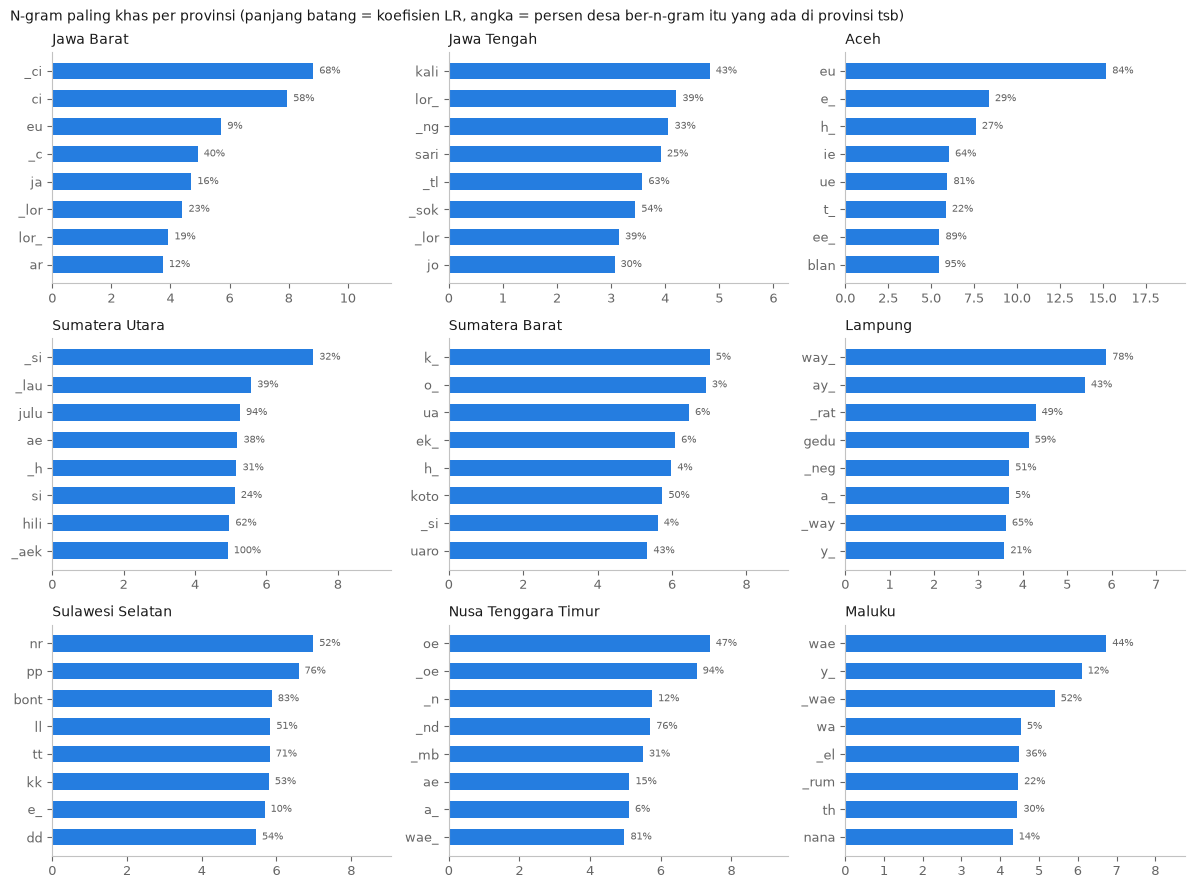

In [4]:
PILIHAN = ["Jawa Barat", "Jawa Tengah", "Aceh", "Sumatera Utara", "Sumatera Barat",
           "Lampung", "Sulawesi Selatan", "Nusa Tenggara Timur", "Maluku"]
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, prov in zip(axes.ravel(), PILIHAN):
    d = ng_prov[ng_prov["provinsi"] == prov].head(8).iloc[::-1]
    ax.barh(d["ngram"], d["koefisien"], color=BIRU, height=0.6)
    for y, (v, p) in enumerate(zip(d["koefisien"], d["persen_di_provinsi"])):
        ax.text(v, y, f"  {p:.0f}%", va="center", color=TEKS2, fontsize=7)
    ax.set_title(prov, fontsize=10, loc="left")
    ax.tick_params(axis="y", labelsize=9)
    ax.set_xlim(0, d["koefisien"].max() * 1.3)
fig.suptitle("N-gram paling khas per provinsi (panjang batang = koefisien LR, angka = persen desa ber-n-gram itu yang ada di provinsi tsb)",
             fontsize=10, color=TEKS, x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGS / "04_ngram_khas.png", dpi=150)
plt.show()

## 2. Tebakan out-of-fold

Model di `models/` dilatih dengan **seluruh** data. Kalau model itu dipakai menebak desa yang sama, hasilnya terlalu bagus karena model sudah pernah melihat desanya.

Jadi untuk analisis kesalahan, data dibagi 5 bagian **per nama unik** (`GroupKFold`). Setiap bagian ditebak oleh model yang dilatih dari 4 bagian lainnya. Hasilnya: setiap desa punya tebakan dari model yang belum pernah melihat namanya.

Proses ini butuh sekitar 8 sampai 10 menit, jadi hasilnya disimpan ke `data/processed/prediksi_oof.parquet` dan dipakai ulang. Hapus file itu kalau ingin menghitung ulang.

In [5]:
OOF_PATH = PROCESSED / "prediksi_oof.parquet"
KELAS = np.array(sorted(df["provinsi"].unique()))

if OOF_PATH.exists():
    oof = pd.read_parquet(OOF_PATH)
    assert (oof["kode_desa"].values == df["kode_desa"].values).all()
    proba = oof[KELAS].values
    print("Memakai hasil tersimpan:", OOF_PATH.relative_to(ROOT))
else:
    proba = np.zeros((len(df), len(KELAS)))
    t0 = time.time()
    lipatan = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for k, (a, b) in enumerate(lipatan.split(df, groups=df["nama_bersih"])):
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True)),
            ("model", LogisticRegression(C=5, max_iter=2000, class_weight="balanced")),
        ])
        pipe.fit(df["nama_bersih"].iloc[a], df["provinsi"].iloc[a])
        assert list(pipe.classes_) == list(KELAS)
        proba[b] = pipe.predict_proba(df["nama_bersih"].iloc[b])
        print(f"lipatan {k + 1}/5 selesai ({time.time() - t0:.0f} detik)")
    oof = pd.concat([df[["kode_desa"]].reset_index(drop=True),
                     pd.DataFrame(proba.astype("float32"), columns=KELAS)], axis=1)
    oof.to_parquet(OOF_PATH, index=False)
    print("Tersimpan:", OOF_PATH.relative_to(ROOT))

df["tebakan"] = KELAS[proba.argmax(axis=1)]
df["keyakinan"] = proba.max(axis=1)
df["tebakan_wilayah"] = df["tebakan"].map(wilayah_dari_provinsi)
df["p_jawa"] = proba[:, [k in PROVINSI_JAWA for k in KELAS]].sum(axis=1)

print(f"Akurasi provinsi (out-of-fold): {(df['tebakan'] == df['provinsi']).mean():.3f}")
print(f"Akurasi wilayah  (out-of-fold): {(df['tebakan_wilayah'] == df['wilayah']).mean():.3f}")

Memakai hasil tersimpan: data\processed\prediksi_oof.parquet
Akurasi provinsi (out-of-fold): 0.401
Akurasi wilayah  (out-of-fold): 0.649


Angkanya sejalan dengan hasil di notebook 02 (provinsi sekitar 0,40, wilayah sekitar 0,65), jadi tebakan ini bisa dipakai untuk analisis.

Catatan: tebakan wilayah di sini diambil dari provinsi yang ditebak, bukan dari model wilayah terpisah. Dengan begitu semua analisis di notebook ini memakai satu model yang sama.

## 3. Confusion matrix wilayah besar

Setiap baris dijumlahkan menjadi 100 persen: baris "Jawa" menunjukkan desa di Jawa ditebak sebagai wilayah apa saja.

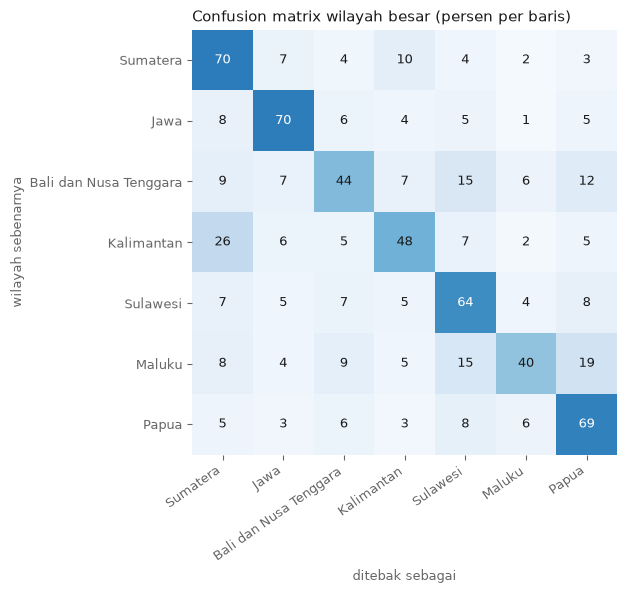

In [6]:
URUT = list(WILAYAH.keys())
cm = confusion_matrix(df["wilayah"], df["tebakan_wilayah"], labels=URUT, normalize="true") * 100

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(URUT)), URUT, rotation=35, ha="right")
ax.set_yticks(range(len(URUT)), URUT)
for i in range(len(URUT)):
    for j in range(len(URUT)):
        ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] > 50 else TEKS)
ax.set_xlabel("ditebak sebagai")
ax.set_ylabel("wilayah sebenarnya")
ax.set_title("Confusion matrix wilayah besar (persen per baris)", loc="left")
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig(FIGS / "04_confusion_wilayah.png", dpi=150)
plt.show()

Pasangan provinsi yang paling sering tertukar. Banyak di antaranya adalah provinsi hasil pemekaran atau bertetangga dengan budaya yang sama, sehingga kesalahan ini wajar.

In [7]:
salah = df[df["tebakan"] != df["provinsi"]]
pasangan = (salah.groupby(["provinsi", "tebakan"]).size().rename("jumlah").reset_index()
            .merge(df["provinsi"].value_counts().rename("total_desa"), left_on="provinsi", right_index=True))
pasangan["persen_dari_provinsi"] = (100 * pasangan["jumlah"] / pasangan["total_desa"]).round(1)
pasangan.sort_values("persen_dari_provinsi", ascending=False).head(15).reset_index(drop=True)

,provinsi,tebakan,jumlah,total_desa,persen_dari_provinsi
0,Daerah Istimewa Yogyakarta,Jawa Tengah,127,438,29.0
1,Banten,Jawa Barat,436,1552,28.1
2,Jawa Timur,Jawa Tengah,1755,8494,20.7
3,Jawa Tengah,Jawa Timur,1738,8563,20.3
4,Daerah Istimewa Yogyakarta,Jawa Timur,85,438,19.4
5,Papua Tengah,Papua Pegunungan,229,1208,19.0
6,Sulawesi Barat,Sulawesi Selatan,115,648,17.7
7,Jawa Barat,Banten,752,5957,12.6
8,Papua Barat,Papua,102,824,12.4
9,Papua Selatan,Papua Pegunungan,85,690,12.3


## 4. Jejak transmigrasi

Program kolonisasi (sejak 1905) dan transmigrasi memindahkan jutaan orang dari Jawa ke pulau lain. Banyak desa baru diberi nama berbahasa Jawa. Kalau benar, desa di provinsi tujuan transmigrasi seharusnya **lebih sering ditebak sebagai provinsi di Jawa** dibanding provinsi lain.

Ukuran yang dipakai: persentase desa di luar Jawa yang tebakannya jatuh ke salah satu provinsi di Jawa.

Pengelompokan:

- **tujuan transmigrasi**: Lampung, Sumatera Selatan, Jambi, kelima provinsi Kalimantan, dan Sulawesi Tengah
- **Bali**: dipisah, karena Bali bukan tujuan transmigrasi tetapi punya warisan budaya Jawa-Hindu yang sama
- **lainnya**: semua provinsi lain di luar Jawa

In [8]:
TUJUAN = ["Lampung", "Sumatera Selatan", "Jambi", "Kalimantan Barat", "Kalimantan Tengah",
          "Kalimantan Selatan", "Kalimantan Timur", "Kalimantan Utara", "Sulawesi Tengah"]

def kelompok(prov):
    if prov in TUJUAN:
        return "tujuan transmigrasi"
    if prov == "Bali":
        return "Bali"
    return "lainnya"

luar = df[df["wilayah"] != "Jawa"].copy()
luar["kelompok"] = luar["provinsi"].map(kelompok)
luar["ditebak_jawa"] = luar["tebakan_wilayah"] == "Jawa"

per_kelompok = luar.groupby("kelompok").agg(jumlah_desa=("kode_desa", "size"),
                                            persen_ditebak_jawa=("ditebak_jawa", "mean"))
per_kelompok["persen_ditebak_jawa"] = (100 * per_kelompok["persen_ditebak_jawa"]).round(1)
per_kelompok

,jumlah_desa,persen_ditebak_jawa
kelompok,,
Bali,716,17.9
lainnya,41008,4.3
tujuan transmigrasi,16763,8.4


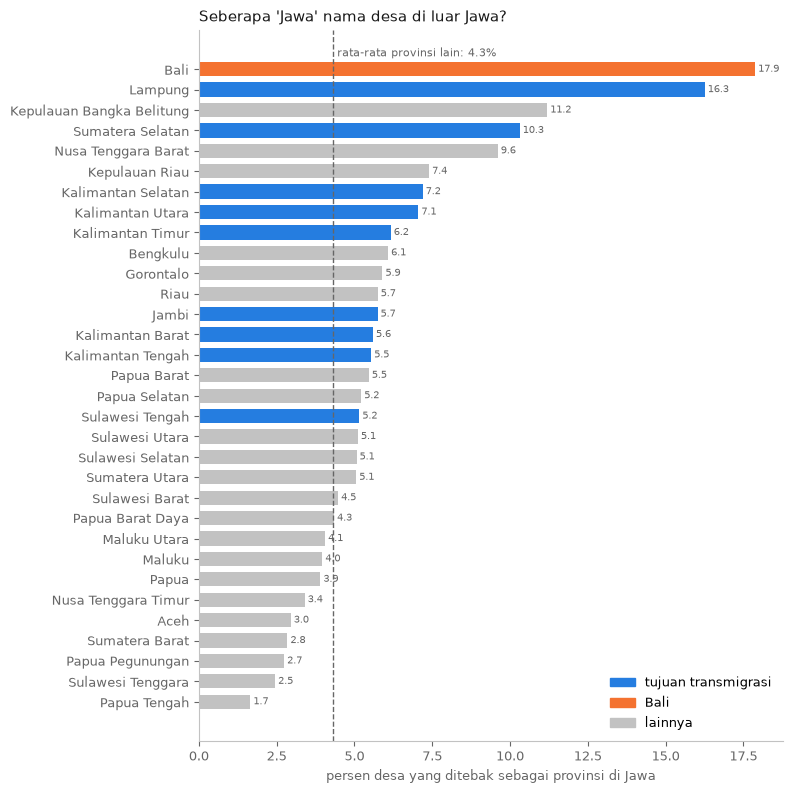

In [9]:
per_prov = (luar.groupby("provinsi").agg(jumlah_desa=("kode_desa", "size"), persen=("ditebak_jawa", "mean"))
            .assign(persen=lambda d: 100 * d["persen"]).sort_values("persen"))
per_prov["kelompok"] = per_prov.index.map(kelompok)
warna = per_prov["kelompok"].map({"tujuan transmigrasi": BIRU, "Bali": ORANYE, "lainnya": ABU})
dasar = 100 * luar.loc[luar["kelompok"] == "lainnya", "ditebak_jawa"].mean()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(per_prov.index, per_prov["persen"], color=warna, height=0.7)
ax.axvline(dasar, color=TEKS2, linestyle="--", linewidth=1)
ax.text(dasar, len(per_prov) - 0.5, f" rata-rata provinsi lain: {dasar:.1f}%", color=TEKS2, fontsize=8, va="bottom")
for y, v in enumerate(per_prov["persen"]):
    ax.text(v, y, f" {v:.1f}", va="center", fontsize=7, color=TEKS2)
ax.set_xlabel("persen desa yang ditebak sebagai provinsi di Jawa")
ax.set_title("Seberapa 'Jawa' nama desa di luar Jawa?", loc="left")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BIRU, label="tujuan transmigrasi"), Patch(color=ORANYE, label="Bali"),
                   Patch(color=ABU, label="lainnya")], loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(FIGS / "04_transmigrasi_provinsi.png", dpi=150)
plt.show()

Peta per kabupaten. Provinsi di Jawa sendiri digambar abu-abu karena tidak dihitung.

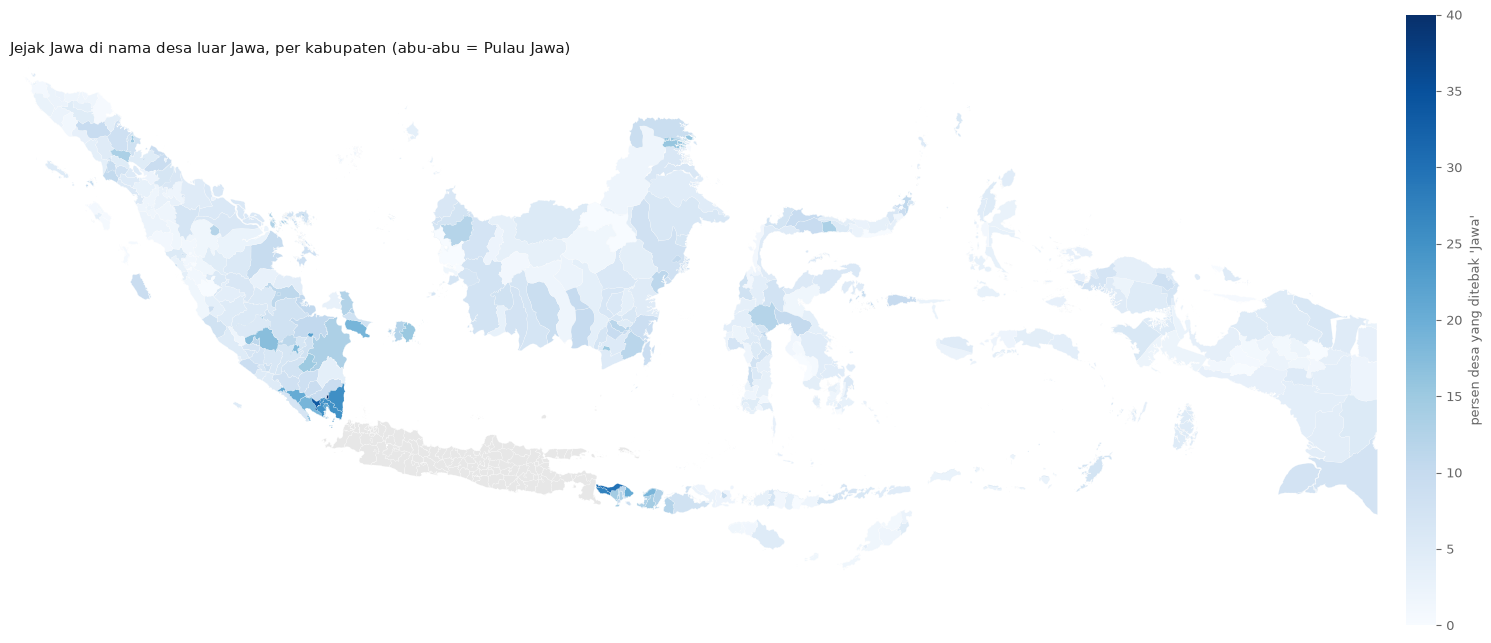

In [10]:
per_kab = luar.groupby("kode_kabupaten")["ditebak_jawa"].mean() * 100

fig, ax = plt.subplots(figsize=(15, 6.5))
gambar_peta(ax, per_kab, level="kabupaten", cmap="Blues", vmin=0, vmax=40,
            label="persen desa yang ditebak 'Jawa'")
ax.set_title("Jejak Jawa di nama desa luar Jawa, per kabupaten (abu-abu = Pulau Jawa)", loc="left")
plt.tight_layout()
plt.savefig(FIGS / "04_peta_jejak_jawa.png", dpi=150)
plt.show()

In [11]:
top_kab = (luar.groupby(["kabupaten", "provinsi"])
           .agg(jumlah_desa=("kode_desa", "size"), persen_ditebak_jawa=("ditebak_jawa", "mean"))
           .query("jumlah_desa >= 20")
           .sort_values("persen_ditebak_jawa", ascending=False).head(15))
top_kab["persen_ditebak_jawa"] = (100 * top_kab["persen_ditebak_jawa"]).round(1)
top_kab

,,jumlah_desa,persen_ditebak_jawa
kabupaten,provinsi,,
Kota Metro,Lampung,22,45.5
Kabupaten Pringsewu,Lampung,131,33.6
Kabupaten Buleleng,Bali,148,29.7
Kabupaten Jembrana,Bali,51,27.5
Kabupaten Lampung Timur,Lampung,264,25.4
Kabupaten Lampung Selatan,Lampung,260,25.0
Kabupaten Pesawaran,Lampung,148,25.0
Kota Palembang,Sumatera Selatan,107,22.4
Kota Bandar Lampung,Lampung,126,21.4


Contoh nama desa di Lampung yang paling yakin ditebak sebagai provinsi di Jawa:

In [12]:
(luar[(luar["provinsi"] == "Lampung") & luar["ditebak_jawa"]]
 .sort_values("keyakinan", ascending=False)
 .drop_duplicates("nama_bersih")
 [["nama_asli", "kabupaten", "tebakan", "keyakinan"]].head(15).round(2).reset_index(drop=True))

,nama_asli,kabupaten,tebakan,keyakinan
0,Ciherang,Kabupaten Tanggamus,Jawa Barat,0.94
1,Triharjo,Kabupaten Lampung Selatan,Daerah Istimewa Yogyakarta,0.91
2,Girikarto,Kabupaten Lampung Timur,Daerah Istimewa Yogyakarta,0.82
3,Sukacari,Kabupaten Lampung Timur,Banten,0.79
4,Rawa Selapan,Kabupaten Lampung Selatan,Daerah Khusus Ibukota Jakarta,0.76
5,Ciamis,Kabupaten Lampung Utara,Jawa Barat,0.75
6,Sumbersari Bantul,Kota Metro,Daerah Istimewa Yogyakarta,0.75
7,Mekarjaya,Kabupaten Lampung Barat,Jawa Barat,0.75
8,Sukamulya,Kabupaten Pringsewu,Jawa Barat,0.74
9,Singosari,Kabupaten Tanggamus,Daerah Istimewa Yogyakarta,0.73


### Cek silang tanpa model

Supaya temuan ini tidak hanya bergantung pada model, hitung juga secara langsung: berapa persen nama desa yang mengandung unsur kata Jawa yang umum dipakai untuk nama tempat, yaitu rejo, harjo, mulyo, sido, karto, wono, tirto, purwo, dan joyo.

In [13]:
POLA_JAWA = r"rejo|harjo|mulyo|sido|karto|wono|tirto|purwo|joyo"
df["unsur_jawa"] = df["nama_bersih"].str.contains(POLA_JAWA)
cek = (df.groupby("provinsi")["unsur_jawa"].mean() * 100).round(1).rename("persen_berunsur_jawa")
cek = cek.to_frame().join(per_prov["persen"].round(1).rename("persen_ditebak_jawa_model"))
cek.sort_values("persen_berunsur_jawa", ascending=False).head(15)

,persen_berunsur_jawa,persen_ditebak_jawa_model
provinsi,,
Daerah Istimewa Yogyakarta,31.7,NaN
Jawa Tengah,12.8,NaN
Jawa Timur,12.8,NaN
Lampung,12.8,16.3
Sumatera Selatan,4.9,10.3
Bengkulu,2.8,6.1
Kalimantan Timur,2.7,6.2
Jambi,1.6,5.7
Sumatera Utara,1.6,5.1


### Desa yang memakai nama daerah asal di Jawa

Contoh di atas memperlihatkan sesuatu yang lebih jelas lagi: ada desa di Lampung bernama "Ciamis", "Mojokerto", "Singosari", dan "Sumbersari Bantul". Para pendatang menamai desa barunya dengan nama kampung halamannya.

Di sini dihitung desa di luar Jawa yang namanya memuat nama kabupaten/kota di Jawa sebagai kata utuh. Nama kabupaten yang juga merupakan kata umum dibuang, karena kecocokannya kebetulan: batu, batang, banjar, bandung, tegal, lebak, malang, serang, pati, sampang, kudus, subang, garut. Kediri juga dibuang, karena "Kediri" di Bali dan Lombok adalah nama asli setempat.

In [14]:
import re

KATA_UMUM = {"batu", "batang", "banjar", "bandung", "tegal", "lebak", "malang", "serang",
             "pati", "sampang", "kudus", "subang", "garut", "kediri"}
nama_kab_jawa = (df.loc[df["wilayah"] == "Jawa", "kabupaten"].drop_duplicates()
                 .str.replace(r"^(Kabupaten|Kota)( Administrasi)?\s+", "", regex=True).str.lower())
nama_kab_jawa = sorted(set(n for n in nama_kab_jawa if "jakarta" not in n and "kepulauan" not in n) - KATA_UMUM)
pola_asal = re.compile(r"\b(" + "|".join(map(re.escape, nama_kab_jawa)) + r")\b")

luar["asal_jawa"] = luar["nama_bersih"].str.extract(pola_asal, expand=False)
bernama_asal = luar.dropna(subset=["asal_jawa"])
print(f"{len(bernama_asal)} desa di luar Jawa memakai nama kabupaten/kota di Jawa")
print("Per provinsi:", bernama_asal["provinsi"].value_counts().head(6).to_dict())
(bernama_asal.groupby("asal_jawa")
 .agg(jumlah=("kode_desa", "size"), provinsi=("provinsi", lambda s: ", ".join(s.value_counts().index[:3])),
      contoh=("nama_asli", lambda s: ", ".join(s.unique()[:3])))
 .sort_values("jumlah", ascending=False).head(20))

96 desa di luar Jawa memakai nama kabupaten/kota di Jawa
Per provinsi: {'Lampung': 41, 'Sumatera Selatan': 16, 'Bengkulu': 10, 'Sumatera Utara': 4, 'Kalimantan Barat': 4, 'Sulawesi Utara': 4}


,jumlah,provinsi,contoh
asal_jawa,,,
purworejo,12,"Lampung, Sulawesi Utara, Sumatera Selatan","Purworejo, Linggang Purworejo, Purworejo Timur"
surabaya,12,"Lampung, Sumatera Selatan, Nusa Tenggara Barat","Surabaya, Surabaya Timur, Surabaya Ilir"
sukoharjo,9,"Lampung, Sumatera Selatan","Sukoharjo, Sukoharjo I, Sukoharjo II"
sukabumi,6,"Lampung, Sumatera Selatan","Sukabumi, Bandar Sukabumi, Sukabumi Indah"
sidoarjo,4,"Sumatera Utara, Lampung, Sulawesi Tengah","Sidoarjo II Ramunia, Sidoarjo"
wonosobo,4,"Aceh, Bengkulu, Lampung",Wonosobo
bogor,4,"Bengkulu, Papua Barat","Kampung Bogor, Bogor Baru, Babakan Bogor"
banyumas,4,"Lampung, Sumatera Utara, Sumatera Selatan","Banyumas, Banyumas Asri"
semarang,3,"Bengkulu, Lampung, Kalimantan Barat","Semarang, Semarang Jaya, Suti Semarang"


## 5. Kandidat salah kode wilayah

Kandidat: desa yang tebakan modelnya sangat yakin (keyakinan minimal 0,9) dan **wilayah besarnya** berbeda dari labelnya. Wilayah besar dipakai (bukan provinsi) supaya provinsi pemekaran yang memang mirip tidak ikut terdaftar.

Kolom `provinsi_lain_dengan_nama_sama` membantu memilah: kalau nama yang sama juga ada di provinsi lain, kemungkinan besar itu bukan salah kode, melainkan nama yang memang dipakai di beberapa tempat.

In [15]:
prov_per_nama = df.groupby("nama_bersih")["provinsi"].nunique()
kandidat = df[(df["keyakinan"] >= 0.9) & (df["tebakan_wilayah"] != df["wilayah"])].copy()
kandidat["provinsi_lain_dengan_nama_sama"] = kandidat["nama_bersih"].map(prov_per_nama) - 1
kandidat = kandidat.sort_values("keyakinan", ascending=False)[
    ["kode_desa", "nama_asli", "kabupaten", "provinsi", "tebakan", "keyakinan", "provinsi_lain_dengan_nama_sama"]
]
kandidat["keyakinan"] = kandidat["keyakinan"].round(3)
kandidat.to_csv(PROCESSED / "kandidat_salah_kode.csv", index=False)
print(f"{len(kandidat)} kandidat dari {len(df)} desa ({100 * len(kandidat) / len(df):.2f} persen)")
kandidat.head(25).reset_index(drop=True)

62 kandidat dari 83758 desa (0.07 persen)


,kode_desa,nama_asli,kabupaten,provinsi,tebakan,keyakinan,provinsi_lain_dengan_nama_sama
0,81.02.17.2003,Weer Frawaf,Kabupaten Maluku Tenggara,Maluku,Papua Barat Daya,0.992,0
1,72.03.06.2015,Long,Kabupaten Donggala,Sulawesi Tengah,Kalimantan Utara,0.970,0
2,61.05.04.2005,Air Nyuruk,Kabupaten Sintang,Kalimantan Barat,Kepulauan Bangka Belitung,0.964,0
3,75.05.04.2012,Tumba,Kabupaten Gorontalo Utara,Gorontalo,Kalimantan Tengah,0.963,1
4,12.01.05.2007,Tumba,Kabupaten Tapanuli Tengah,Sumatera Utara,Kalimantan Tengah,0.963,1
5,11.01.03.2001,Suaq Bakung,Kabupaten Aceh Selatan,Aceh,Kalimantan Timur,0.959,0
6,36.03.31.2001,Solear,Kabupaten Tangerang,Banten,Maluku,0.958,0
7,33.12.25.2006,Golo,Kabupaten Wonogiri,Jawa Tengah,Nusa Tenggara Timur,0.955,3
8,82.01.04.2013,Golo,Kabupaten Halmahera Barat,Maluku Utara,Nusa Tenggara Timur,0.955,3
9,95.07.19.2002,Golo,Kabupaten Lanny Jaya,Papua Pegunungan,Nusa Tenggara Timur,0.955,3


## 6. Ringkasan temuan

Sel berikut mencetak angka-angka kunci untuk laporan dan slide. Interpretasinya ditulis di bawah dan perlu dicek ulang setiap kali notebook dijalankan ulang.

In [16]:
r = per_kelompok["persen_ditebak_jawa"]
print(f"Desa luar Jawa yang ditebak 'Jawa': tujuan transmigrasi {r['tujuan transmigrasi']}%, "
      f"Bali {r['Bali']}%, provinsi lain {r['lainnya']}%")
print("Provinsi tertinggi:", ", ".join(f"{p} ({v:.1f}%)" for p, v in per_prov["persen"].iloc[::-1].head(4).items()))
print("Kabupaten tertinggi:", ", ".join(f"{k} ({v}%)" for (k, _), v in top_kab["persen_ditebak_jawa"].head(4).items()))
print(f"Kandidat salah kode wilayah: {len(kandidat)} desa")

Desa luar Jawa yang ditebak 'Jawa': tujuan transmigrasi 8.4%, Bali 17.9%, provinsi lain 4.3%
Provinsi tertinggi: Bali (17.9%), Lampung (16.3%), Kepulauan Bangka Belitung (11.2%), Sumatera Selatan (10.3%)
Kabupaten tertinggi: Kota Metro (45.5%), Kabupaten Pringsewu (33.6%), Kabupaten Buleleng (29.7%), Kabupaten Jembrana (27.5%)
Kandidat salah kode wilayah: 62 desa


**Interpretasi (draf untuk laporan):**

1. **N-gram khas sesuai dengan pengetahuan bahasa daerah.** Contohnya `_ci` dan `eu` untuk Sunda, `eu`/`ie`/`blang` untuk Aceh, konsonan ganda (`pp`, `ll`, `kk`) dan `bont` (bonto) untuk Bugis-Makassar, `oe` untuk Timor, `way` untuk Lampung, `koto` untuk Minangkabau, `aek` dan `lau` untuk Batak. Model menemukan pola ini sendiri tanpa diberi tahu.
2. **Kesalahan model tidak acak.** Sebagian besar kesalahan terjadi antara provinsi bertetangga atau provinsi hasil pemekaran yang budayanya sama (DIY dan Jawa Tengah, Banten dan Jawa Barat, provinsi-provinsi Papua). Di tingkat wilayah, sekitar seperempat desa Kalimantan ditebak Sumatera, kemungkinan karena keduanya berbagi kosakata Melayu (sungai, tanjung, pulau, teluk).
3. **Jejak transmigrasi paling kuat di Lampung**, terutama di Kota Metro dan Pringsewu, yang memang pusat kolonisasi sejak awal abad ke-20. Buktinya juga terlihat tanpa model: ada desa di luar Jawa yang memakai nama kabupaten/kota di Jawa (Purworejo, Sukoharjo, Banyumas, Klaten, Bantul, dan lain-lain), dan hampir separuhnya ada di Lampung. Di provinsi tujuan lain (Kalimantan, Sulawesi Tengah), angkanya tidak jauh di atas provinsi lain. Dugaan yang perlu dicek di laporan: desa transmigrasi yang lebih baru sering diberi nama berbahasa Indonesia umum (misalnya "Sumber Makmur", "Karya Jaya"), bukan nama Jawa.
4. **Bali sering ditebak Jawa**, bukan karena transmigrasi tetapi karena kedekatan bahasa dan budaya Jawa-Bali.
5. **Kandidat salah kode wilayah sangat sedikit**, dan sebagian besar adalah nama pendek yang kebetulan mirip pola daerah lain atau nama yang memang dipakai di banyak provinsi. Kesimpulan jujurnya: tidak ditemukan tanda jelas kesalahan kode di data Kepmendagri 2025. Ini tetap hasil yang layak dilaporkan.